In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import folium

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import warnings
warnings.filterwarnings("ignore")

In [4]:
patients = pd.read_csv("patients.csv")
conditions = pd.read_csv("conditions.csv")
encounters = pd.read_csv("encounters.csv")
observations = pd.read_csv("observations.csv")
medications = pd.read_csv("medications.csv")
procedures = pd.read_csv("procedures.csv")
allergies = pd.read_csv("allergies.csv")
immunizations = pd.read_csv("immunizations.csv")
careplans = pd.read_csv("careplans.csv")
claims = pd.read_csv("claims.csv")
claims_transactions = pd.read_csv("claims_transactions.csv")
devices = pd.read_csv("devices.csv")
imaging = pd.read_csv("imaging_studies.csv")
organizations = pd.read_csv("organizations.csv")
providers = pd.read_csv("providers.csv")
payers = pd.read_csv("payers.csv")
payer_transitions = pd.read_csv("payer_transitions.csv")
supplies = pd.read_csv("supplies.csv")

In [5]:
patients.head()

,Id,BIRTHDATE,DEATHDATE,SSN,DRIVERS,PASSPORT,PREFIX,FIRST,LAST,SUFFIX,...,BIRTHPLACE,ADDRESS,CITY,STATE,COUNTY,ZIP,LAT,LON,HEALTHCARE_EXPENSES,HEALTHCARE_COVERAGE
0,b9c610cd-28a6-4636-ccb6-c7a0d2a4cb85,2019-02-17,NaN,999-65-3251,NaN,NaN,NaN,Damon455,Langosh790,NaN,...,Middleborough Massachusetts US,620 Lynch Tunnel Apt 0,Springfield,Massachusetts,Hampden County,1104.0,42.080389,-72.480431,9039.1645,7964.1255
1,c1f1fcaa-82fd-d5b7-3544-c8f9708b06a8,2005-07-04,NaN,999-49-3323,S99941126,NaN,NaN,Thi53,Wunsch504,NaN,...,Danvers Massachusetts US,972 Tillman Branch Suite 48,Bellingham,Massachusetts,Norfolk County,NaN,42.035213,-71.482519,402723.4150,14064.1350
2,339144f8-50e1-633e-a013-f361391c4cff,1998-05-11,NaN,999-10-8743,S99996708,X75063318X,Mr.,Chi716,Greenfelder433,NaN,...,Athens Athens Prefecture GR,1060 Bernhard Crossroad Suite 15,Boston,Massachusetts,Suffolk County,2131.0,42.292557,-71.061160,571935.8725,787.5375
3,d488232e-bf14-4bed-08c0-a82f34b6a197,2003-01-28,NaN,999-56-6057,S99929424,NaN,Ms.,Phillis443,Walter473,NaN,...,Boston Massachusetts US,677 Ritchie Terrace,Hingham,Massachusetts,Plymouth County,2043.0,42.200491,-70.916076,582557.8030,104782.2070
4,217f95a3-4e10-bd5d-fb67-0cfb5e8ba075,1993-12-23,NaN,999-91-4320,S99991143,X44132498X,Mr.,Jerrold404,Herzog843,NaN,...,Boston Massachusetts US,276 Bernier Branch,Revere,Massachusetts,Suffolk County,NaN,42.381875,-70.999286,475826.8550,18067.0950


In [6]:
print("Rows:", patients.shape[0])
print("Columns:", patients.shape[1])

Rows: 1163
Columns: 25


In [7]:
patients.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1163 entries, 0 to 1162
Data columns (total 25 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Id                   1163 non-null   object 
 1   BIRTHDATE            1163 non-null   object 
 2   DEATHDATE            163 non-null    object 
 3   SSN                  1163 non-null   object 
 4   DRIVERS              948 non-null    object 
 5   PASSPORT             887 non-null    object 
 6   PREFIX               918 non-null    object 
 7   FIRST                1163 non-null   object 
 8   LAST                 1163 non-null   object 
 9   SUFFIX               16 non-null     object 
 10  MAIDEN               331 non-null    object 
 11  MARITAL              779 non-null    object 
 12  RACE                 1163 non-null   object 
 13  ETHNICITY            1163 non-null   object 
 14  GENDER               1163 non-null   object 
 15  BIRTHPLACE           1163 non-null   o

In [8]:
patients.describe(include="all")

,Id,BIRTHDATE,DEATHDATE,SSN,DRIVERS,PASSPORT,PREFIX,FIRST,LAST,SUFFIX,...,BIRTHPLACE,ADDRESS,CITY,STATE,COUNTY,ZIP,LAT,LON,HEALTHCARE_EXPENSES,HEALTHCARE_COVERAGE
count,1163,1163,163,1163,948,887,918,1163,1163,16,...,1163,1163,1163,1163,1163,618.000000,1163.000000,1163.000000,1.163000e+03,1.163000e+03
unique,1163,987,163,1163,941,887,3,1002,477,3,...,317,1163,256,1,13,NaN,NaN,NaN,NaN,NaN
top,b9c610cd-28a6-4636-ccb6-c7a0d2a4cb85,1913-06-10,2009-11-13,999-65-3251,S99993912,X75063318X,Mr.,Francisco472,Ledner144,JD,...,Boston Massachusetts US,620 Lynch Tunnel Apt 0,Boston,Massachusetts,Middlesex County,NaN,NaN,NaN,NaN,NaN
freq,1,11,1,1,2,1,431,5,10,7,...,111,1,116,1163,241,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,2001.263754,42.255261,-71.336063,1.256248e+06,1.717684e+05
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,443.449141,0.286969,0.618013,1.148747e+06,4.885749e+05
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,1001.000000,41.299942,-73.445165,8.259920e+02,0.000000e+00
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,1835.000000,42.100121,-71.516412,4.426256e+05,1.293600e+03
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,2118.500000,42.307061,-71.140665,1.142154e+06,1.747219e+04
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,2190.000000,42.448367,-71.004105,1.900910e+06,2.051068e+05


In [9]:
missing = patients.isnull().sum()

missing = missing[missing > 0].sort_values(ascending=False)

print(missing)

SUFFIX       1147
DEATHDATE    1000
MAIDEN        832
ZIP           545
MARITAL       384
PASSPORT      276
PREFIX        245
DRIVERS       215
dtype: int64


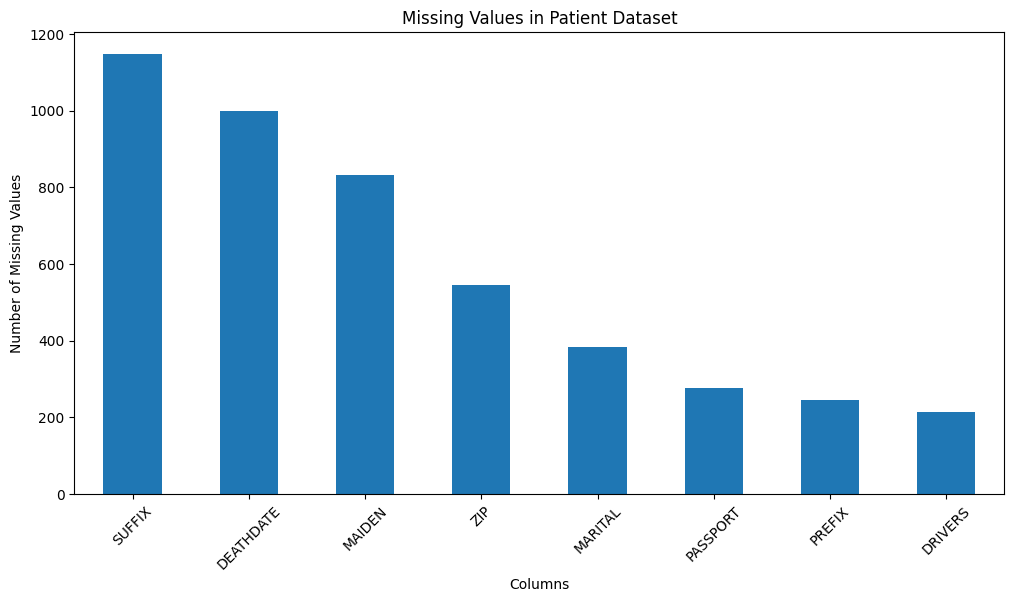

In [10]:
plt.figure(figsize=(12, 6))

missing.plot(kind="bar")

plt.title("Missing Values in Patient Dataset")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")

plt.xticks(rotation=45)
plt.show()

In [11]:
patients["BIRTHDATE"] = pd.to_datetime(
    patients["BIRTHDATE"],
    errors="coerce"
)

In [12]:
reference_date = pd.Timestamp("2026-01-01")

patients["AGE"] = (
    (reference_date - patients["BIRTHDATE"]).dt.days / 365.25
).astype(int)

In [13]:
patients[["BIRTHDATE", "AGE", "GENDER"]].head()

,BIRTHDATE,AGE,GENDER
0,2019-02-17,6,M
1,2005-07-04,20,F
2,1998-05-11,27,M
3,2003-01-28,22,F
4,1993-12-23,32,M


In [14]:
gender_counts = patients["GENDER"].value_counts()

print(gender_counts)

GENDER
F    616
M    547
Name: count, dtype: int64


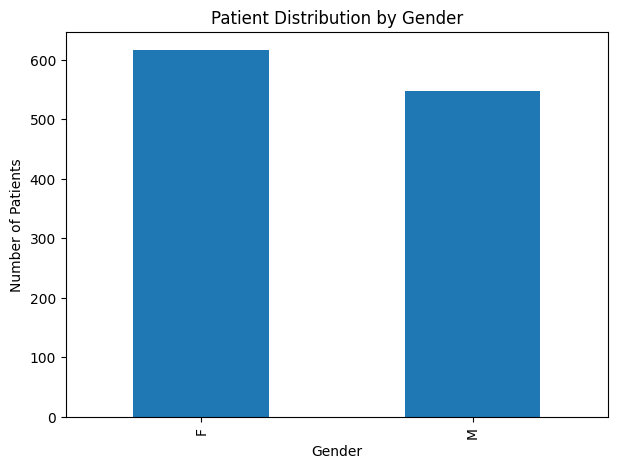

In [15]:
plt.figure(figsize=(7, 5))

gender_counts.plot(kind="bar")

plt.title("Patient Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Patients")

plt.show()

In [16]:
fig = px.bar(
    gender_counts,
    x=gender_counts.index,
    y=gender_counts.values,
    labels={
        "x": "Gender",
        "y": "Number of Patients"
    },
    title="Patient Distribution by Gender"
)

fig.show()

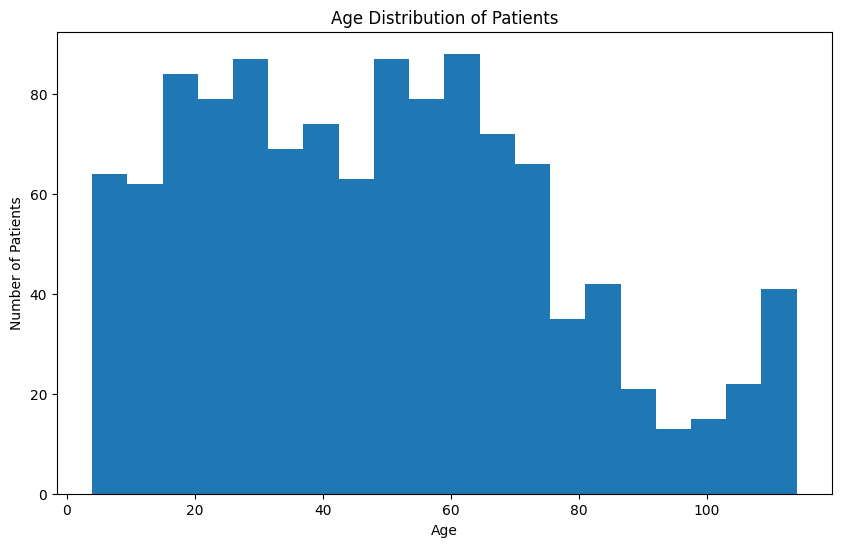

In [17]:
plt.figure(figsize=(10, 6))

plt.hist(
    patients["AGE"].dropna(),
    bins=20
)

plt.title("Age Distribution of Patients")
plt.xlabel("Age")
plt.ylabel("Number of Patients")

plt.show()

In [18]:
fig = px.histogram(
    patients,
    x="AGE",
    nbins=30,
    title="Patient Age Distribution"
)

fig.show()

In [19]:
diagnosis_counts = (
    conditions["DESCRIPTION"]
    .value_counts()
    .head(15)
)

print(diagnosis_counts)

DESCRIPTION
Full-time employment (finding)                      13805
Stress (finding)                                     5137
Part-time employment (finding)                       2426
Social isolation (finding)                           1243
Viral sinusitis (disorder)                           1233
Limited social contact (finding)                     1200
Not in labor force (finding)                         1077
Victim of intimate partner abuse (finding)            819
Acute viral pharyngitis (disorder)                    678
Acute bronchitis (disorder)                           571
Reports of violence in the environment (finding)      565
Normal pregnancy                                      527
Received higher education (finding)                   523
Body mass index 30+ - obesity (finding)               463
Risk activity involvement (finding)                   392
Name: count, dtype: int64


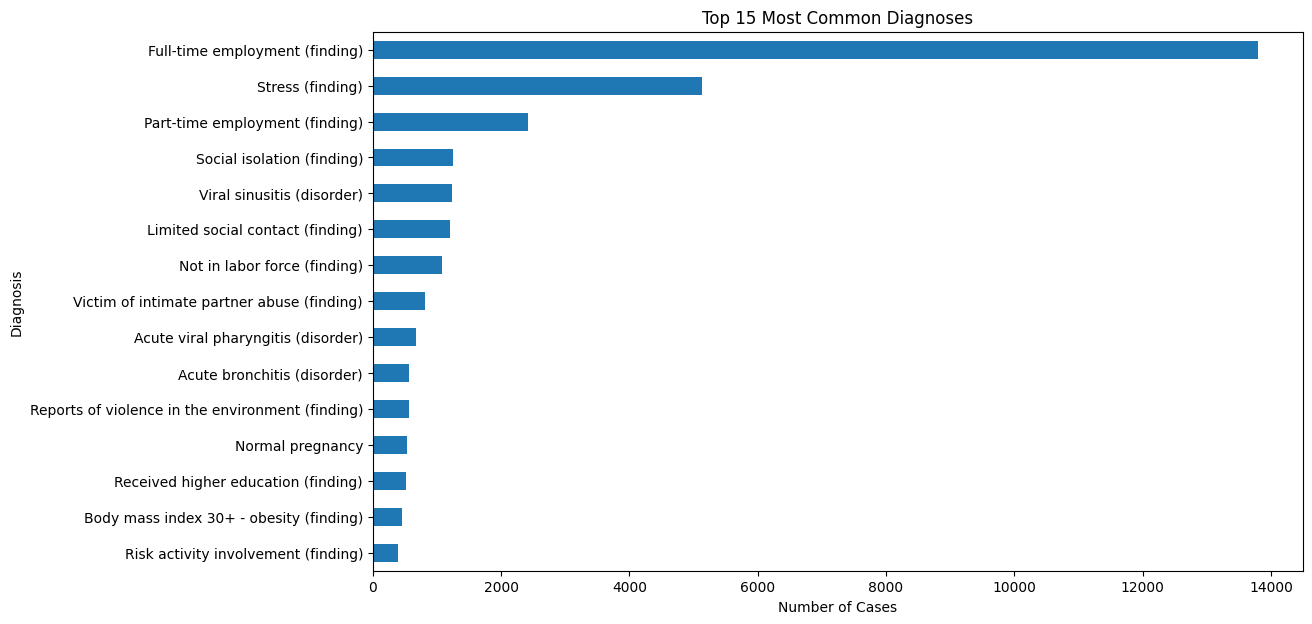

In [20]:
plt.figure(figsize=(12, 7))

diagnosis_counts.sort_values().plot(kind="barh")

plt.title("Top 15 Most Common Diagnoses")
plt.xlabel("Number of Cases")
plt.ylabel("Diagnosis")

plt.show()

In [21]:
fig = px.bar(
    diagnosis_counts.sort_values(),
    orientation="h",
    title="Top 15 Most Common Diagnoses",
    labels={
        "value": "Number of Cases",
        "index": "Diagnosis"
    }
)

fig.show()

In [22]:
diagnoses_per_patient = (
    conditions.groupby("PATIENT")
    .size()
    .reset_index(name="DIAGNOSIS_COUNT")
)

diagnoses_per_patient.head()

,PATIENT,DIAGNOSIS_COUNT
0,00126cb9-8460-4747-e302-c3609684531e,18
1,00209bf2-8e4d-06d1-82a4-daad02f25829,70
2,00ae3b00-9500-efc1-2758-a93d3f77e650,57
3,00c9ca99-6b9f-add4-8759-f7dfee6ea1a4,37
4,0142b69f-57f0-9a08-4e2d-65a2b77fdea7,50


In [23]:
encounters_per_patient = (
    encounters.groupby("PATIENT")
    .size()
    .reset_index(name="ENCOUNTER_COUNT")
)

encounters_per_patient.head()

,PATIENT,ENCOUNTER_COUNT
0,00126cb9-8460-4747-e302-c3609684531e,60
1,00209bf2-8e4d-06d1-82a4-daad02f25829,76
2,00ae3b00-9500-efc1-2758-a93d3f77e650,40
3,00c9ca99-6b9f-add4-8759-f7dfee6ea1a4,47
4,0142b69f-57f0-9a08-4e2d-65a2b77fdea7,41


In [24]:
medications_per_patient = (
    medications.groupby("PATIENT")
    .size()
    .reset_index(name="MEDICATION_COUNT")
)

medications_per_patient.head()

,PATIENT,MEDICATION_COUNT
0,00126cb9-8460-4747-e302-c3609684531e,39
1,00209bf2-8e4d-06d1-82a4-daad02f25829,72
2,00ae3b00-9500-efc1-2758-a93d3f77e650,3
3,00c9ca99-6b9f-add4-8759-f7dfee6ea1a4,14
4,0142b69f-57f0-9a08-4e2d-65a2b77fdea7,33


In [25]:
procedures_per_patient = (
    procedures.groupby("PATIENT")
    .size()
    .reset_index(name="PROCEDURE_COUNT")
)

procedures_per_patient.head()

,PATIENT,PROCEDURE_COUNT
0,00126cb9-8460-4747-e302-c3609684531e,133
1,00209bf2-8e4d-06d1-82a4-daad02f25829,83
2,00ae3b00-9500-efc1-2758-a93d3f77e650,57
3,00c9ca99-6b9f-add4-8759-f7dfee6ea1a4,55
4,0142b69f-57f0-9a08-4e2d-65a2b77fdea7,65


In [26]:
patient_features = patients[
    [
        "Id",
        "AGE",
        "GENDER",
        "RACE",
        "ETHNICITY",
        "CITY",
        "STATE",
        "LAT",
        "LON",
        "HEALTHCARE_EXPENSES",
        "HEALTHCARE_COVERAGE"
    ]
].copy()

In [27]:
patient_features.rename(
    columns={"Id": "PATIENT"},
    inplace=True
)

In [28]:
patient_features = patient_features.merge(
    diagnoses_per_patient,
    on="PATIENT",
    how="left"
)

In [29]:
patient_features = patient_features.merge(
    encounters_per_patient,
    on="PATIENT",
    how="left"
)

In [30]:
patient_features = patient_features.merge(
    medications_per_patient,
    on="PATIENT",
    how="left"
)

In [31]:
patient_features = patient_features.merge(
    procedures_per_patient,
    on="PATIENT",
    how="left"
)

In [32]:
patient_features.head()

,PATIENT,AGE,GENDER,RACE,ETHNICITY,CITY,STATE,LAT,LON,HEALTHCARE_EXPENSES,HEALTHCARE_COVERAGE,DIAGNOSIS_COUNT,ENCOUNTER_COUNT,MEDICATION_COUNT,PROCEDURE_COUNT
0,b9c610cd-28a6-4636-ccb6-c7a0d2a4cb85,6,M,white,nonhispanic,Springfield,Massachusetts,42.080389,-72.480431,9039.1645,7964.1255,NaN,12,2.0,6.0
1,c1f1fcaa-82fd-d5b7-3544-c8f9708b06a8,20,F,white,nonhispanic,Bellingham,Massachusetts,42.035213,-71.482519,402723.4150,14064.1350,6.0,20,5.0,24.0
2,339144f8-50e1-633e-a013-f361391c4cff,27,M,white,nonhispanic,Boston,Massachusetts,42.292557,-71.061160,571935.8725,787.5375,19.0,19,22.0,51.0
3,d488232e-bf14-4bed-08c0-a82f34b6a197,22,F,white,nonhispanic,Hingham,Massachusetts,42.200491,-70.916076,582557.8030,104782.2070,10.0,31,2.0,86.0
4,217f95a3-4e10-bd5d-fb67-0cfb5e8ba075,32,M,black,nonhispanic,Revere,Massachusetts,42.381875,-70.999286,475826.8550,18067.0950,14.0,10,1.0,17.0


In [33]:
count_columns = [
    "DIAGNOSIS_COUNT",
    "ENCOUNTER_COUNT",
    "MEDICATION_COUNT",
    "PROCEDURE_COUNT"
]

patient_features[count_columns] = (
    patient_features[count_columns]
    .fillna(0)
)

In [34]:
patient_features["GENDER"] = (
    patient_features["GENDER"]
    .map({
        "M": 0,
        "F": 1
    })
)

In [35]:
print(patient_features["GENDER"].value_counts(dropna=False))

GENDER
1    616
0    547
Name: count, dtype: int64


In [36]:
features = [
    "AGE",
    "GENDER",
    "DIAGNOSIS_COUNT",
    "ENCOUNTER_COUNT",
    "MEDICATION_COUNT",
    "PROCEDURE_COUNT",
    "HEALTHCARE_EXPENSES"
]

In [37]:
cluster_data = patient_features[features].copy()

In [38]:
cluster_data = cluster_data.replace(
    [np.inf, -np.inf],
    np.nan
)

cluster_data = cluster_data.fillna(0)

In [39]:
scaler = StandardScaler()

X = scaler.fit_transform(cluster_data)

In [40]:
inertia = []

K = range(2, 11)

for k in K:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X)

    inertia.append(model.inertia_)

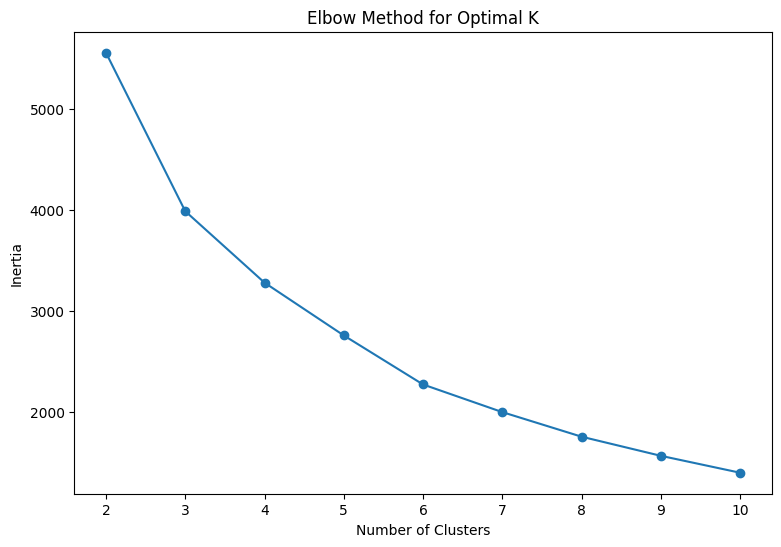

In [41]:
plt.figure(figsize=(9, 6))

plt.plot(K, inertia, marker="o")

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")

plt.show()

In [42]:
silhouette_scores = []

for k in range(2, 11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X)

    score = silhouette_score(X, labels)

    silhouette_scores.append(score)

    print(
        "K =", k,
        "Silhouette Score =", round(score, 4)
    )

K = 2 Silhouette Score = 0.8392
K = 3 Silhouette Score = 0.3149
K = 4 Silhouette Score = 0.3358
K = 5 Silhouette Score = 0.3397
K = 6 Silhouette Score = 0.3731
K = 7 Silhouette Score = 0.3721
K = 8 Silhouette Score = 0.3659
K = 9 Silhouette Score = 0.3663
K = 10 Silhouette Score = 0.3478


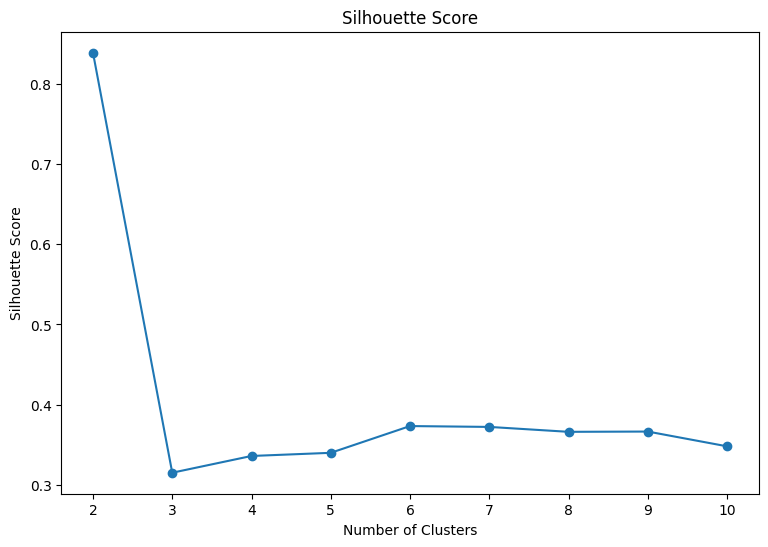

In [43]:
plt.figure(figsize=(9, 6))

plt.plot(
    range(2, 11),
    silhouette_scores,
    marker="o"
)

plt.title("Silhouette Score")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")

plt.show()

In [44]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

patient_features["CLUSTER"] = kmeans.fit_predict(X)

In [45]:
print(
    patient_features["CLUSTER"]
    .value_counts()
    .sort_index()
)

CLUSTER
0    394
1    402
2     11
3    356
Name: count, dtype: int64


In [46]:
cluster_summary = (
    patient_features
    .groupby("CLUSTER")[features]
    .mean()
)

cluster_summary

,AGE,GENDER,DIAGNOSIS_COUNT,ENCOUNTER_COUNT,MEDICATION_COUNT,PROCEDURE_COUNT,HEALTHCARE_EXPENSES
CLUSTER,,,,,,,
0,36.357868,0.000000,20.065990,26.581218,16.515228,39.111675,7.165207e+05
1,76.196517,0.636816,52.679104,75.584577,78.519900,91.114428,2.111080e+06
2,92.909091,0.363636,286.545455,599.727273,1190.272727,605.909091,4.997141e+06
3,29.750000,1.000000,16.457865,39.337079,14.789326,70.561798,7.727113e+05


In [47]:
fig = px.scatter(
    patient_features,
    x="AGE",
    y="ENCOUNTER_COUNT",
    color="CLUSTER",
    hover_data=[
        "DIAGNOSIS_COUNT",
        "MEDICATION_COUNT",
        "PROCEDURE_COUNT",
        "HEALTHCARE_EXPENSES"
    ],
    title="Patient Clusters"
)

fig.show()

In [48]:
fig = px.scatter_3d(
    patient_features,
    x="AGE",
    y="ENCOUNTER_COUNT",
    z="HEALTHCARE_EXPENSES",
    color="CLUSTER",
    hover_data=[
        "DIAGNOSIS_COUNT",
        "MEDICATION_COUNT",
        "PROCEDURE_COUNT"
    ],
    title="3D Visualization of Patient Clusters"
)

fig.show()

In [49]:
map_data = patient_features.dropna(
    subset=["LAT", "LON"]
).copy()

In [50]:
center_lat = map_data["LAT"].mean()
center_lon = map_data["LON"].mean()

ehr_map = folium.Map(
    location=[center_lat, center_lon],
    zoom_start=5
)

In [51]:
center_lat = map_data["LAT"].mean()
center_lon = map_data["LON"].mean()

ehr_map = folium.Map(
    location=[center_lat, center_lon],
    zoom_start=5
)

In [52]:
for _, row in map_data.head(500).iterrows():

    folium.CircleMarker(
        location=[
            row["LAT"],
            row["LON"]
        ],
        radius=4,
        popup=f"""
        Patient: {row['PATIENT']}<br>
        Age: {row['AGE']}<br>
        Cluster: {row['CLUSTER']}
        """,
        fill=True
    ).add_to(ehr_map)

In [54]:
ehr_map

In [55]:
condition_location = conditions.merge(
    patients[
        [
            "Id",
            "CITY",
            "STATE",
            "LAT",
            "LON"
        ]
    ],
    left_on="PATIENT",
    right_on="Id",
    how="left"
)

In [56]:
state_diagnoses = (
    condition_location
    .groupby("STATE")
    .size()
    .sort_values(ascending=False)
)

state_diagnoses.head(10)

STATE
Massachusetts    38094
dtype: int64

In [58]:
fig = px.bar(
    state_diagnoses.head(15),
    title="Top States by Recorded Diagnoses",
    labels={
        "value": "Number of Diagnoses",
        "STATE": "State"
    }
)

fig.show()

In [59]:
top_medications = (
    medications["DESCRIPTION"]
    .value_counts()
    .head(15)
)

top_medications

DESCRIPTION
lisinopril 10 MG Oral Tablet                                                                            8166
Hydrochlorothiazide 25 MG Oral Tablet                                                                   7509
amLODIPine 2.5 MG Oral Tablet                                                                           5942
insulin human  isophane 70 UNT/ML / Regular Insulin  Human 30 UNT/ML Injectable Suspension [Humulin]    4068
24 HR Metformin hydrochloride 500 MG Extended Release Oral Tablet                                       2996
Simvastatin 10 MG Oral Tablet                                                                           2489
NDA020503 200 ACTUAT Albuterol 0.09 MG/ACTUAT Metered Dose Inhaler                                      2341
120 ACTUAT Fluticasone propionate 0.044 MG/ACTUAT Metered Dose Inhaler                                  2337
Nitroglycerin 0.4 MG/ACTUAT Mucosal Spray                                                               1635
Simvast

In [60]:
fig = px.bar(
    top_medications.sort_values(),
    orientation="h",
    title="Top 15 Medications"
)

fig.show()

In [61]:
top_procedures = (
    procedures["DESCRIPTION"]
    .value_counts()
    .head(15)
)

top_procedures

DESCRIPTION
Assessment of health and social care needs (procedure)                                  8901
Depression screening (procedure)                                                        7727
Depression screening using Patient Health Questionnaire Two-Item score (procedure)      6940
Assessment of substance use (procedure)                                                 6199
Medication Reconciliation (procedure)                                                   6032
Assessment of anxiety (procedure)                                                       4954
Assessment using Alcohol Use Disorders Identification Test - Consumption (procedure)    2765
Screening for drug abuse (procedure)                                                    2748
Evaluation of uterine fundal height                                                     2717
Auscultation of the fetal heart                                                         2717
Screening for domestic abuse (procedure)                  

In [62]:
fig = px.bar(
    top_procedures.sort_values(),
    orientation="h",
    title="Top 15 Medical Procedures"
)

fig.show()

In [63]:
fig = px.histogram(
    patient_features,
    x="HEALTHCARE_EXPENSES",
    nbins=40,
    title="Distribution of Healthcare Expenses"
)

fig.show()

In [64]:
fig = px.box(
    patient_features,
    x="CLUSTER",
    y="HEALTHCARE_EXPENSES",
    color="CLUSTER",
    title="Healthcare Expenses by Patient Cluster"
)

fig.show()

In [65]:
print("Total Patients:", len(patient_features))

print(
    "Total Diagnoses:",
    len(conditions)
)

print(
    "Total Encounters:",
    len(encounters)
)

print(
    "Total Medications:",
    len(medications)
)

print(
    "Total Procedures:",
    len(procedures)
)

print(
    "Number of Patient Clusters:",
    patient_features["CLUSTER"].nunique()
)

Total Patients: 1163
Total Diagnoses: 38094
Total Encounters: 61459
Total Medications: 56430
Total Procedures: 83823
Number of Patient Clusters: 4


In [66]:
cluster_summary

,AGE,GENDER,DIAGNOSIS_COUNT,ENCOUNTER_COUNT,MEDICATION_COUNT,PROCEDURE_COUNT,HEALTHCARE_EXPENSES
CLUSTER,,,,,,,
0,36.357868,0.000000,20.065990,26.581218,16.515228,39.111675,7.165207e+05
1,76.196517,0.636816,52.679104,75.584577,78.519900,91.114428,2.111080e+06
2,92.909091,0.363636,286.545455,599.727273,1190.272727,605.909091,4.997141e+06
3,29.750000,1.000000,16.457865,39.337079,14.789326,70.561798,7.727113e+05
